# 02 — Noise and the Unknown class

**Unknown** means the doctor could not decide whether there is a murmur, almost always because the recording
is too noisy: crying, voices, breathing, the stethoscope moving. It weighs 3 in the metric, so detecting it
matters. But there are only 54 Unknown patients in training, too few for a network to learn it from alone.

This notebook measures noise **without any hand labels**, from the audio alone, so the measures also work on
the hidden set:

1. **A pretrained sound tagger** (AudioSet). What does it hear in stethoscope audio?
2. **Our own noise "lanes"**: simple measurements of how noise behaves, built after listening to training
   recordings.
3. **Do they separate Unknown?** And do they wrongly react to murmurs (which would push Present to Unknown)?

Everything uses **training patients only**; the test split is not touched.

`RECOMPUTE = False` reads the stored results in `results/`. `True` recomputes them: the tagger needs a GPU,
about 4 min; the lanes about 15 min on 4 CPU cores.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from murmur.core.paths import results_dir
from murmur.data import circor, split
from murmur.evaluate import lanes
from murmur.preprocess import audioset
from murmur.viz import lanes as lane_plot

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
RECOMPUTE = False

patients, recordings, s = circor.patients(), circor.recordings(), split.load()
train = s[s.split == "train"]
train_recs = recordings[recordings["patient_id"].isin(train.index)]
patient_of = recordings["patient_id"]
print(len(train), "training patients,", len(train_recs), "recordings")

753 training patients, 2535 recordings


## 1. A pretrained sound tagger: what does it hear?

PANNs Cnn14 is trained on AudioSet: 2 million YouTube clips, 527 sound classes, including speech, baby
crying, breathing, rustling and "heart sounds". We run it over every recording and keep the classes that
match the noise we expect, folded into five groups.

Our audio is 4 kHz, while the model was trained on 32 kHz: everything above 2 kHz, where much of what makes a
sound recognisable lives, is missing.

In [2]:
path = results_dir() / "tagger" / "summary.tsv"
if RECOMPUTE:
    summary, _ = audioset.tag_all(recordings, circor.audio)
    summary.to_csv(path, sep="\t")
summary = pd.read_csv(path, sep="\t", index_col="recording_id")

groups = pd.DataFrame({name: summary[cols].max(axis=1) for name, cols in audioset.CURVES.items()})
pd.DataFrame({"recordings where it ever passes 0.1": (groups > 0.1).mean(),
              "passes 0.5": (groups > 0.5).mean()}).map("{:.0%}".format)

,recordings where it ever passes 0.1,passes 0.5
heart,63%,17%
speech,17%,4%
crying,0%,0%
breathing,0%,0%
handling,0%,0%


**The tagger is deaf to crying, breathing and handling:** they never pass 0.1 in any of the 3163 recordings.
Listening to training recordings shows these sounds are common, so they are not rare; the tagger cannot
hear them here. Two reasons:
- the missing high frequencies;
- the stethoscope hears the child **through the body**, so a baby's own crying arrives loud, low and distorted,
  nothing like a recording of a crying baby.

It does pick up some background **speech**, which travels through the air, and it recognises a **heartbeat**.
That last one is useful: a recording where it does not recognise a heartbeat is often Unknown.

## 2. Our own noise lanes

Four measurements, computed over time from the audio (code: `murmur/preprocess/noise.py`):

| lane | what it measures | rises for |
|---|---|---|
| **not beat-locked** | the share of the sound that does **not** repeat with the heartbeat | anything that is not the heart |
| voice | a pitched sound (above 220 Hz), weighted by how strongly its harmonics stand out | the baby crying or babbling |
| above heart band | energy above 400 Hz that does not repeat with the beat | breathing, hiss |
| sudden off-beat | abrupt changes at moments that are not S1/S2 | movement, bumps |

**Not beat-locked** is the key one. Only the heart repeats with every beat; a murmur too, since it sits in
every systole. Each beat is stretched to a common length using the experts' segmentation, followed by beat
tracking where the segmentation stops, and compared with the same point in its neighbouring beats. What
they share is heart; the leftover is noise. It is the REPET method from music source separation, where
it separates a repeating accompaniment from a singing voice, locked here to the heartbeat. It is locked to
the heartbeat rather than to any repetition because steady breathing repeats too.

Four training recordings, with the tagger's curves and ours:

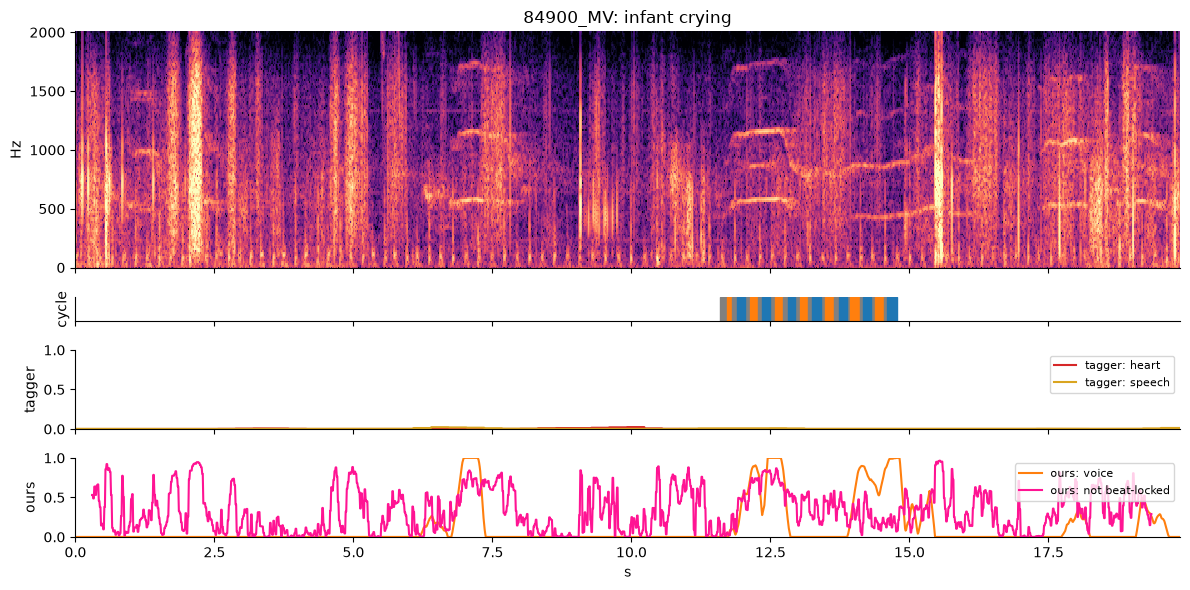

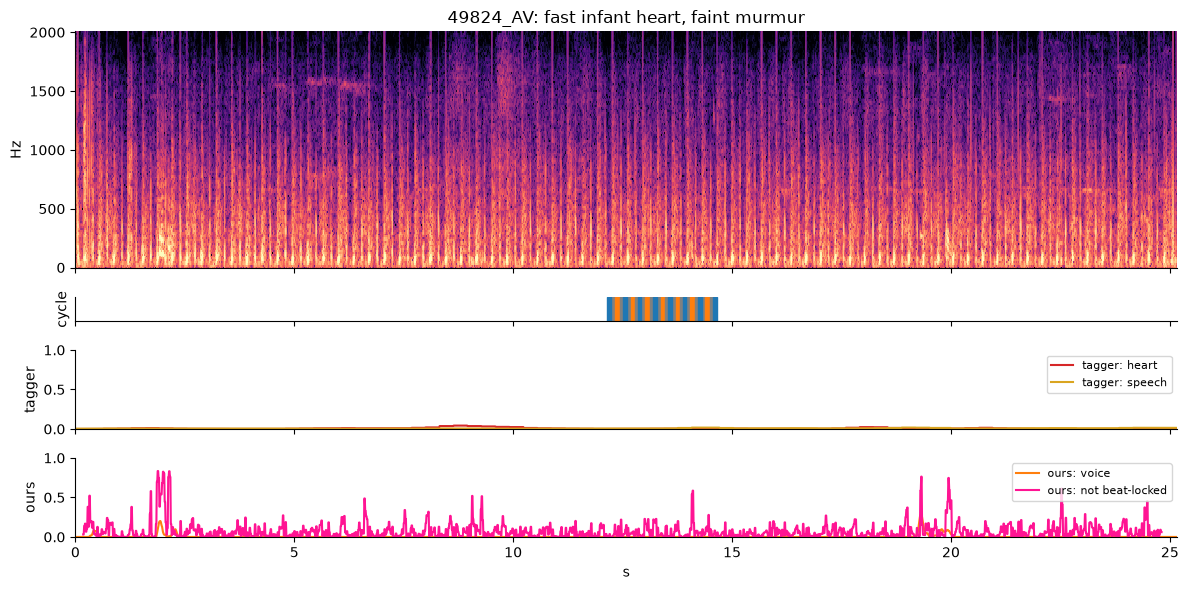

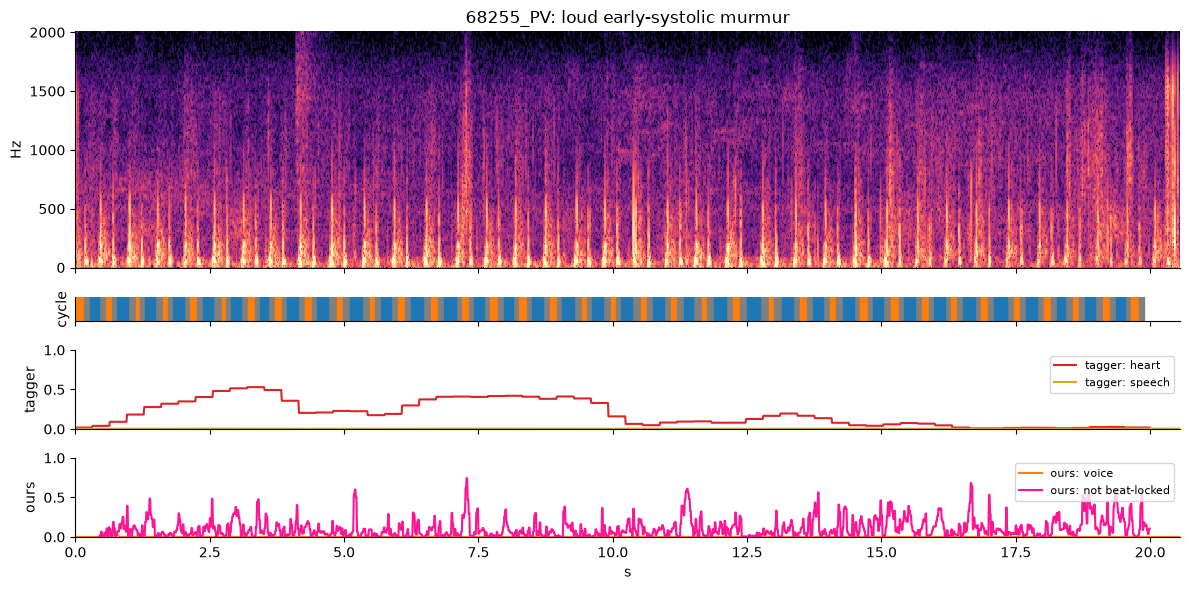

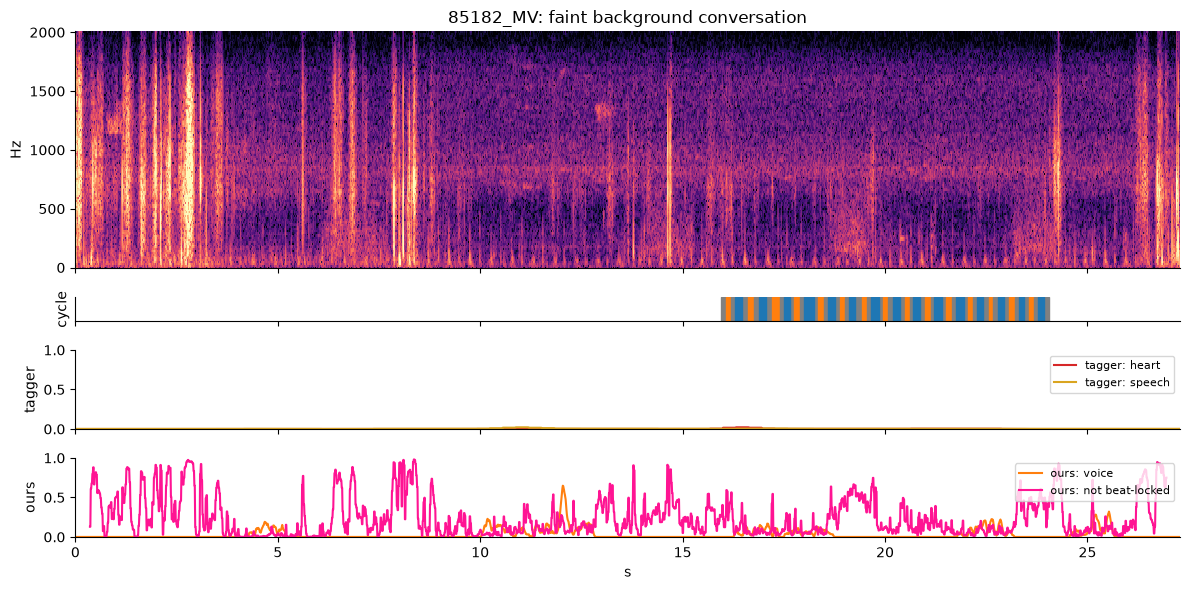

In [3]:
examples = {"84900_MV": "infant crying", "49824_AV": "fast infant heart, faint murmur",
            "68255_PV": "loud early-systolic murmur", "85182_MV": "faint background conversation"}
for rid, what in examples.items():
    kept = np.load(results_dir() / "tagger" / "examples" / f"{rid}.npy").astype(float)
    lane_plot.lanes(recordings.loc[rid], audioset.kept_to_curves(kept), title=f"{rid}: {what}")
    plt.show()

On the crying recording, the tagger's curves stay flat while ours rise. On the two murmur recordings,
**not beat-locked stays low**: the murmur repeats with the beat, so it is counted as heart, not noise.

## 3. Do the lanes separate Unknown?

In [4]:
path = results_dir() / "noise-lanes" / "recordings.tsv"
if RECOMPUTE:   # run the notebook with OMP_NUM_THREADS=1 set beforehand, or the 4 processes oversubscribe the CPU
    table = lanes.table(train_recs.index)
    table["tagger_heart_mean"] = summary.loc[table.index, "heart_mean"]
    table.to_csv(path, sep="\t")
table = pd.read_csv(path, sep="\t", index_col="recording_id")
per = lanes.per_patient(table, patient_of)
murmur = patients.loc[per.index, "murmur"]
infant = patients.loc[per.index, "age"].eq("Infant")
lanes.auc_table(per, murmur, infant).round(3)

,AUC Unknown,infants,older,AUC Present vs Absent
feature,,,,
nbl_median,0.844,0.720,0.871,0.415
nbl_p90,0.785,0.630,0.809,0.351
voice_share,0.688,0.592,0.690,0.464
voice_mean,0.673,0.592,0.673,0.457
above_median,0.669,0.622,0.621,0.640
above_p90,0.672,0.615,0.642,0.563
above_left_median,0.660,0.670,0.618,0.567
above_left_p90,0.704,0.624,0.688,0.522
sudden_share,0.464,0.537,0.465,0.420


AUC: 0.5 = chance, 1 = perfect, below 0.5 = lower values go with the class (the tagger's heart-likeness is
*low* for Unknown, so 0.17 means 0.83).

- **Not beat-locked (median) reaches 0.844**, on par with the pretrained tagger, with no model at all.
- Its **Present vs Absent is 0.415**: Present patients are slightly *more* beat-locked, so murmurs are not
  read as noise.
- **Above heart band** reacts to murmurs (0.64 plain, 0.57 on the leftover) and is not used.
- **Sudden off-beat** does nothing (0.46).
- Every lane is weaker **within infants**, where Unknown is most common (20 % of infants vs 6 % of children).

In [5]:
folds = train.loc[per.index, "fold"]
ours = ["nbl_median", "nbl_p90", "voice_share", "voice_mean", "above_left_median", "sudden_share"]
pd.Series({"tagger heart only": lanes.oof_auc_unknown(per, murmur, folds, ["tagger_heart_mean"]),
           "our lanes only": lanes.oof_auc_unknown(per, murmur, folds, ours),
           "tagger + our lanes": lanes.oof_auc_unknown(per, murmur, folds, ours + ["tagger_heart_mean"])},
          name="out-of-fold AUC for Unknown").round(3)

tagger heart only     0.818
our lanes only        0.821
tagger + our lanes    0.857
Name: out-of-fold AUC for Unknown, dtype: float64

Combined in a logistic regression (fitted on four folds, scored on the fifth), they reach 0.857, partly complementary.

## 4. Do the lanes mistake murmurs for noise?

The costly error would be reading a loud murmur as noise. Among Present patients, using their recordings at a
murmur location, do the lanes rise with the murmur's **grade** (loudness) and **pitch**?

In [6]:
lanes.leak_check(table[["nbl_median", "above_left_median", "above_median", "voice_share"]], patients, recordings).round(2)

,ρ with grade,ρ with pitch
lane,,
nbl_median,-0.11,0.08
above_left_median,0.18,0.45
above_median,0.14,0.50
voice_share,-0.12,0.05


Not beat-locked does not rise with either, so it is clean. The above-band lanes rise with pitch: high-pitched
murmurs reach above 400 Hz.

In [7]:
rho, auc = lanes.heart_rate_check(table, patients, recordings)
display(rho.round(2))
auc.round(3)

,Infant/Absent,Infant/Present,Child/Absent,Child/Present
nbl_median,-0.04,0.04,-0.14,-0.14
above_left_median,0.22,0.16,0.20,0.01
above_median,0.28,0.39,0.26,0.22


all         0.640
infants     0.526
children    0.552
Name: AUC Unknown from heart rate, dtype: float64

**Heart rate** (from the segmentation; infants are around 134 bpm, children around 103) raises the above-band
energy: fast beats leave little time for each sound to fade. Not beat-locked is unaffected. Heart rate alone
says almost nothing about Unknown once age is held fixed (0.53 in infants, 0.55 in children).

## 5. Why there are no hand labels

We first planned to label noise by hand (crying, speech, handling…) with time intervals, to train a noise
detector. After one session it was set aside: most short noises in stethoscope audio cannot be named
confidently, and guessed labels would validate nothing. Listening, without labelling, still mattered: it
shaped the lanes. Steady breathing repeating led to the beat-locked version; a faint voice saturating the
voice lane led to weighting it by harmonic strength; a strong murmur leaking into the above-band lane led to
measuring it on the leftover.

## What this means

| finding | consequence |
|---|---|
| The tagger is deaf to crying, breathing and handling at 4 kHz | Do not use it to find noise; it is useful only for heart-likeness |
| Not beat-locked separates Unknown at AUC 0.844 and ignores murmurs | The noise measure to use; also a candidate input to the CNN (notebook 04) |
| Above heart band reacts to murmurs and heart rate | Not used |
| Every measure is weak within infants | Infants' Unknown is not explained by noise level alone: open |
| Not beat-locked needs beat positions | On the hidden set: the `.tsv` files if provided, otherwise a beat tracker |